# Customer Segmentation Analysis

## Oasis Infobyte Data Analytics Internship
### Level 1 – Task 2

**Project By:** Pornima Onkar Nerkar

## Objective
To segment customers of an e-commerce business based on their purchasing behaviour using RFM (Recency, Frequency, Monetary) analysis and the K-Means clustering algorithm.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Project Workflow
1. Data loading and inspection
2. Data cleaning and preprocessing
3. Exploratory data analysis
4. RFM feature engineering
5. Feature scaling
6. K-Means clustering
7. Cluster visualization and profiling
8. Business insights and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total Missing Values: 136534


In [7]:
# Create a cleaned copy of the dataset

df_clean = df.copy()

# Remove rows with missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove rows with missing Description
df_clean = df_clean.dropna(subset=['Description'])

# Remove cancelled invoices (InvoiceNo starts with C)
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove non-positive quantities and prices
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
]

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Original dataset shape: (541909, 8)
Cleaned dataset shape: (397884, 8)

Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [8]:
# Calculate total purchase amount for each transaction

df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

# Display the first five rows
df_clean[['InvoiceNo', 'CustomerID', 'Quantity',
          'UnitPrice', 'TotalAmount']].head()

,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalAmount
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34


In [9]:
# Set reference date as one day after the latest transaction
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Display first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [10]:
# Calculate customer statistics

total_customers = rfm.shape[0]

average_purchase_value = (
    df_clean['TotalAmount'].sum() /
    df_clean['InvoiceNo'].nunique()
)

average_purchase_frequency = rfm['Frequency'].mean()

average_customer_value = rfm['Monetary'].mean()

print("Total Customers:", total_customers)
print("Average Purchase Value:", round(average_purchase_value, 2))
print("Average Purchase Frequency:", round(average_purchase_frequency, 2))
print("Average Historical Customer Value (CLV):", round(average_customer_value, 2))

Total Customers: 4338
Average Purchase Value: 480.87
Average Purchase Frequency: 4.27
Average Historical Customer Value (CLV): 2054.27


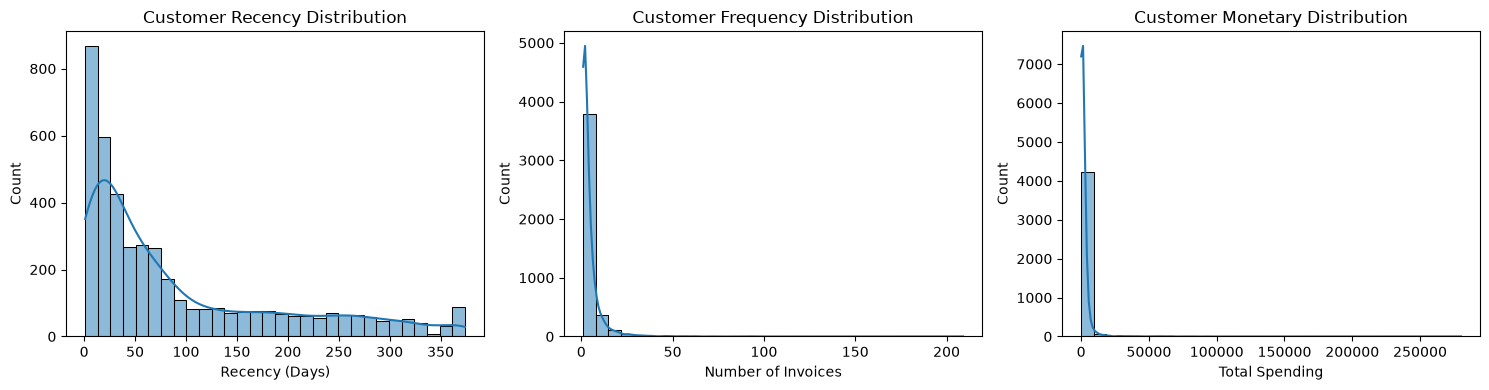

In [11]:
# Visualize RFM distributions

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30, kde=True)
plt.title('Customer Recency Distribution')
plt.xlabel('Recency (Days)')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30, kde=True)
plt.title('Customer Frequency Distribution')
plt.xlabel('Number of Invoices')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30, kde=True)
plt.title('Customer Monetary Distribution')
plt.xlabel('Total Spending')

plt.tight_layout()
plt.show()

In [12]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create a copy of the RFM data
rfm_model = rfm.copy()

# Apply log transformation to reduce skewness
rfm_log = np.log1p(rfm_model[['Recency', 'Frequency', 'Monetary']])

# Standardize the RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert scaled data back to a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

# Display the first five scaled records
rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.706225
12347.0,-2.038734,1.074425,1.411843
12348.0,0.373104,0.386304,0.716489
12349.0,-0.623086,-0.955214,0.698739
12350.0,1.424558,-0.955214,-0.618962


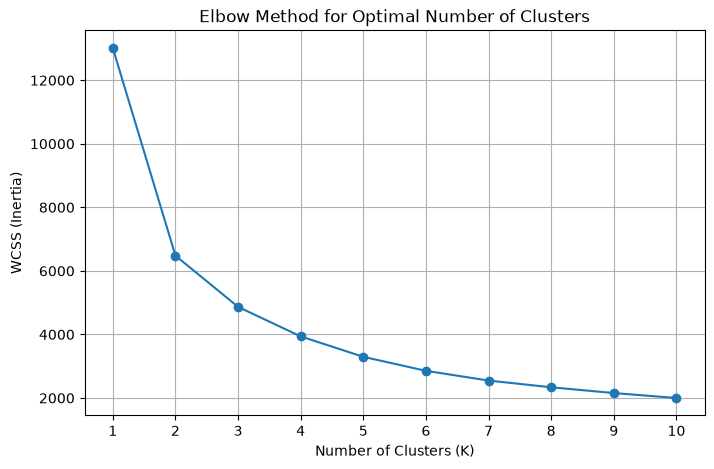

In [13]:
# Import KMeans
from sklearn.cluster import KMeans

# Calculate WCSS (inertia) for different cluster numbers
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [14]:
from sklearn.cluster import KMeans

# Apply K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display customer segments
print("Customer clusters assigned successfully!")
print(rfm.head())

Customer clusters assigned successfully!
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          1  77183.60        2
12347.0           2          7   4310.00        1
12348.0          75          4   1797.24        2
12349.0          19          1   1757.55        0
12350.0         310          1    334.40        3


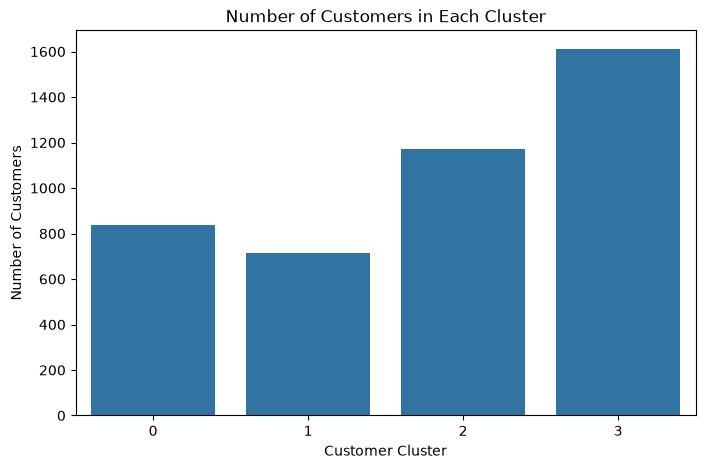

Customer count in each cluster:
Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64


In [15]:
# Count customers in each cluster
cluster_counts = rfm['Cluster'].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

print("Customer count in each cluster:")
print(cluster_counts)

In [16]:
# Calculate average RFM values for each cluster
cluster_profile = rfm.groupby('Cluster')[[
    'Recency', 'Frequency', 'Monetary'
]].mean().round(2)

print("Customer Cluster Profiles:")
print(cluster_profile)

Customer Cluster Profiles:
         Recency  Frequency  Monetary
Cluster                              
0          18.12       2.15    551.82
1          12.13      13.71   8074.27
2          71.08       4.08   1802.83
3         182.50       1.32    343.45


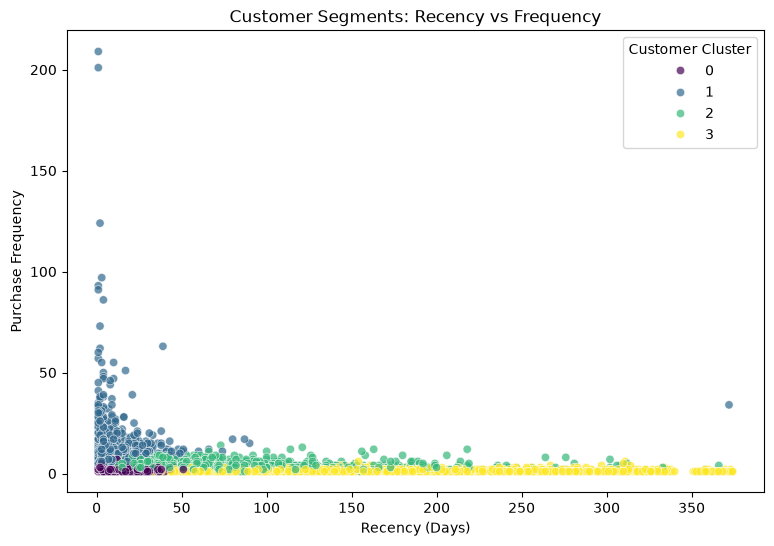

In [17]:
# Visualise clusters using Recency and Frequency
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    alpha=0.7
)

plt.title('Customer Segments: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.legend(title='Customer Cluster')
plt.show()

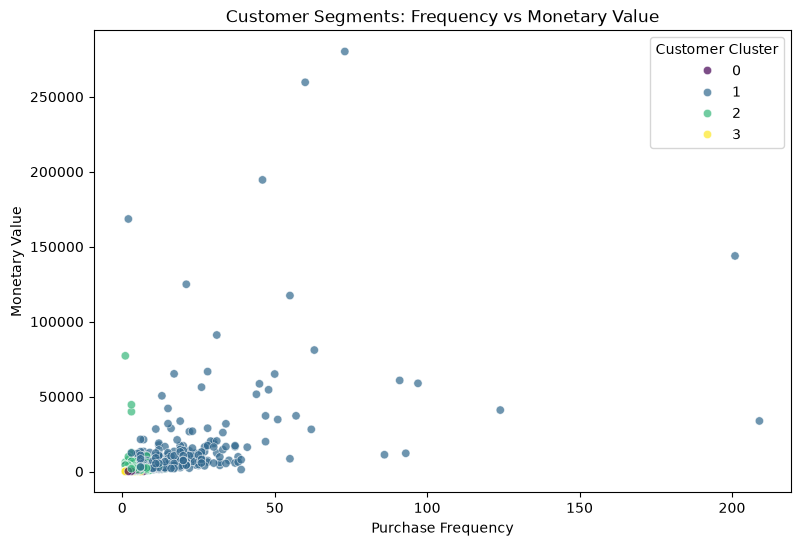

In [18]:
# Visualise clusters using Frequency and Monetary Value
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    alpha=0.7
)

plt.title('Customer Segments: Frequency vs Monetary Value')
plt.xlabel('Purchase Frequency')
plt.ylabel('Monetary Value')
plt.legend(title='Customer Cluster')
plt.show()

## Business Insights and Marketing Recommendations

Based on the RFM analysis and K-Means clustering, four customer segments were identified.

### Cluster 0 – Recent, Occasional Customers
- Customers have purchased recently but have relatively low purchase frequency and spending.
- **Recommendation:** Use welcome-back offers, product recommendations, and personalised promotions to encourage repeat purchases.

### Cluster 1 – Loyal, High-Value Customers
- These customers purchase frequently and have the highest average monetary value.
- **Recommendation:** Provide loyalty rewards, exclusive discounts, VIP benefits, and early access to new products.

### Cluster 2 – Moderately Active Customers
- These customers show moderate purchase frequency and spending but have not purchased as recently as Cluster 0 or Cluster 1.
- **Recommendation:** Use personalised product suggestions, limited-time offers, and targeted campaigns to increase engagement.

### Cluster 3 – At-Risk or Inactive Customers
- These customers have the highest average recency and relatively low purchase frequency and spending.
- **Recommendation:** Run re-engagement campaigns, send special discount coupons, and provide incentives to encourage another purchase.

### Overall Business Findings
- Four distinct customer groups were identified using K-Means clustering.
- Cluster 1 represents the most valuable customer segment.
- Cluster 3 represents customers who may need re-engagement.
- RFM analysis helps businesses understand customer purchasing behaviour and develop targeted marketing strategies.

## Conclusion

This Customer Segmentation Analysis successfully grouped e-commerce customers into four distinct segments using RFM (Recency, Frequency, and Monetary) analysis and the K-Means clustering algorithm.

The analysis included data loading, cleaning, exploratory analysis, RFM feature engineering, feature scaling, elbow method evaluation, clustering, and visualisation.

The results identified different purchasing behaviours, including loyal high-value customers, recent occasional customers, moderately active customers, and at-risk customers.

These findings can help businesses improve customer retention, develop targeted marketing campaigns, increase customer engagement, and make better data-driven decisions.

**Project Status:** Completed

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.